In [1]:
# CELL 1: setup, shared eval code, file lists
import os, sys, io, json, time, glob, resource
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image
from sklearn.cluster import KMeans
from skimage.metrics import structural_similarity

ROOT      = Path("/kaggle/input/datasets/krrishshandilya/dipcoma-trainval")
TEST_ROOT = Path("/kaggle/input/datasets/krrishshandilya/dipcoma-test")
OUT       = Path("/kaggle/working"); OUT.mkdir(exist_ok=True)

os.environ["DIPCOMA_ROOT"] = str(ROOT)          # the shared metric code reads its protocol from here
sys.path.insert(0, str(ROOT / "code"))
import dipcoma_eval as E

BANDS, NB, H, W_ = E.ORDER, E.NB, E.H, E.W
train_files = E.list_patches("train")
val_files   = E.list_patches("val")
test_files  = sorted(glob.glob(str(TEST_ROOT / "**/*.npy"), recursive=True))
print(len(train_files), "train |", len(val_files), "val |", len(test_files), "test patches")

# the test set has to be normalised with the train lo/hi
tp = TEST_ROOT / "protocol.json"
if tp.exists():
    t = json.load(open(tp))
    print("test protocol matches train:", np.allclose(t["lo"], E.PROTO["lo"]) and np.allclose(t["hi"], E.PROTO["hi"]))

# same JPEG quality sweep as the baseline file
QUALITIES = sorted(pd.read_csv(ROOT / "results" / "jpeg_val.csv")["quality"].unique().tolist())
print("JPEG qualities:", QUALITIES)

# run-time knobs: raise the strides for a quick dry run, SSIM is slow so it only runs on every n-th patch
STRIDE_VAL, STRIDE_TEST, SSIM_EVERY = 1, 1, 5

def load_patch(path):
    """(13, 512, 512) float32 in [0, 1] using the protocol's lo/hi."""
    return E.normalise(E.load_dn(path))

x0 = load_patch(train_files[0])
print("patch:", x0.shape, "| range:", float(x0.min()), float(x0.max()))

957 train | 165 val | 396 test patches
JPEG qualities: [1, 2, 3, 4, 5, 6, 10, 20, 30, 50, 70, 85, 95]
patch: (13, 512, 512) | range: 0.005921701900660992 0.7021733522415161


In [2]:
# CELL 2: sample pixel spectra from every train patch
rng = np.random.default_rng(42)
PIX_PER_PATCH = 2000

def sample_pixels(files, n):
    out = []
    for f in files:
        x = load_patch(f).reshape(NB, -1)
        idx = rng.choice(x.shape[1], n, replace=False)
        out.append(x[:, idx].T)
    return np.concatenate(out)

t0 = time.time()
X_train = sample_pixels(train_files, PIX_PER_PATCH)        # (n_pixels, 13), already in [0, 1]
print(X_train.shape, f"{time.time() - t0:.0f}s")

(1914000, 13) 189s


In [3]:
# CELL 3: step 1 - the band-selection autoencoder
dev = "cuda" if torch.cuda.is_available() else "cpu"
mu, sd = X_train.mean(0), X_train.std(0) + 1e-6             # z-score for the AE input only

class BandAE(nn.Module):
    def __init__(self, nb=NB, hidden=8):
        super().__init__()
        self.encoder = nn.Linear(nb, hidden, bias=False)
        self.decoder = nn.Linear(hidden, nb, bias=False)
    def forward(self, x):
        return self.decoder(torch.relu(self.encoder(x)))

torch.manual_seed(0)
model = BandAE().to(dev)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
Xt = torch.tensor((X_train - mu) / sd, dtype=torch.float32)
LAMBDA, EPOCHS, BS = 1e-3, 60, 8192

t_train = time.time()
for epoch in range(EPOCHS):
    perm = torch.randperm(len(Xt))
    total, n = 0.0, 0
    for i in range(0, len(Xt), BS):
        b = Xt[perm[i:i + BS]].to(dev)
        loss = ((model(b) - b) ** 2).mean() + LAMBDA * model.encoder.weight.norm(dim=0).sum()
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item(); n += 1
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"epoch {epoch + 1:02d}/{EPOCHS}  loss {total / n:.4f}")
t_train = time.time() - t_train

# band importance = L2 norm of each band's input-weight column
importance = model.encoder.weight.detach().cpu().norm(dim=0).numpy()
for b, s in sorted(zip(BANDS, importance), key=lambda t: -t[1]):
    print(f"{b:>4}  {s:.3f}")
torch.save(model.state_dict(), OUT / "band_ae.pt")
n_params = sum(p.numel() for p in model.parameters())

epoch 01/60  loss 0.5882
epoch 10/60  loss 0.0206
epoch 20/60  loss 0.0147
epoch 30/60  loss 0.0123
epoch 40/60  loss 0.0109
epoch 50/60  loss 0.0101
epoch 60/60  loss 0.0096
 B10  0.195
 B09  0.157
 B8A  0.151
 B12  0.149
 B11  0.142
 B02  0.136
 B01  0.122
 B08  0.116
 B07  0.115
 B04  0.114
 B03  0.104
 B05  0.078
 B06  0.060


==> OPTIMAL K SELECTED: 6 (Fitness J(b): 0.00274)


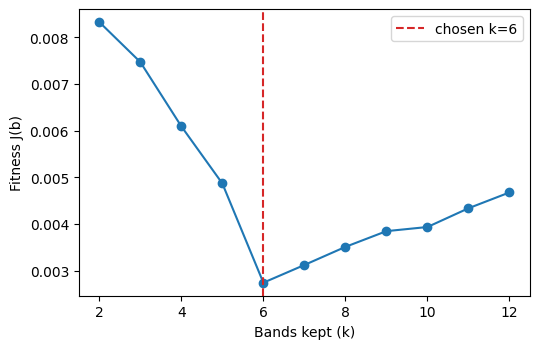

In [4]:
# ==========================================
# REPLACEMENT FOR CELL 4: Automated K-Selection (Approach 4 Fitness)
# ==========================================
n_patch = len(X_train) // PIX_PER_PATCH
cut = int(0.8 * n_patch) * PIX_PER_PATCH
X_fit, X_hold = X_train[:cut], X_train[cut:]

rank = np.argsort(-importance)
MU = 0.005 # Rate penalty hyperparameter

k_candidates = np.arange(2, NB)
fitness_scores = []
losses = []

for k in k_candidates:
    sel = sorted(rank[:k].tolist())
    dis = [i for i in range(NB) if i not in sel]
    
    # Fit regressor on 80% of train
    A = np.c_[X_fit[:, sel], np.ones(len(X_fit))]
    Wk, *_ = np.linalg.lstsq(A, X_fit[:, dis], rcond=None)
    
    # Evaluate on held-out 20% of train
    pred = np.clip(np.c_[X_hold[:, sel], np.ones(len(X_hold))] @ Wk, 0, 1)
    val_mse = ((X_hold[:, dis] - pred) ** 2).mean()
    
    # Calculate Fitness J(b)
    rate = k / NB
    J = val_mse + MU * rate
    
    fitness_scores.append(J)
    losses.append(val_mse)

# Pick optimal k
best_k_idx = np.argmin(fitness_scores)
K_MAIN = int(k_candidates[best_k_idx])

print(f"==> OPTIMAL K SELECTED: {K_MAIN} (Fitness J(b): {fitness_scores[best_k_idx]:.5f})")

plt.figure(figsize=(5.5, 3.6))
plt.plot(k_candidates, fitness_scores, marker="o")
plt.axvline(K_MAIN, ls="--", c="tab:red", label=f"chosen k={K_MAIN}")
plt.xlabel("Bands kept (k)"); plt.ylabel("Fitness J(b)"); plt.legend()
plt.tight_layout(); plt.savefig(OUT / "a3_choose_k_fitness.png", dpi=150); plt.show()

In [5]:
# CELL 5: band subsets for the AE and the baselines, and the regressors for the dropped bands
def top_k(score, k):
    return sorted(np.argsort(-score)[:k].tolist())

def band_entropy(X, bins=256):
    ent = []
    for j in range(X.shape[1]):
        h, _ = np.histogram(X[:, j], bins=bins, range=(0, 1))
        p = h[h > 0] / h.sum()
        ent.append(-(p * np.log2(p)).sum())
    return np.array(ent)

var_score = X_train.var(0)
ent_score = band_entropy(X_train)

def kmeans_subset(k, n_sub=20000):
    idx = np.random.default_rng(0).choice(len(X_train), min(n_sub, len(X_train)), replace=False)
    B = X_train[idx].T                                      # one row per band
    B = (B - B.mean(1, keepdims=True)) / (B.std(1, keepdims=True) + 1e-8)
    km = KMeans(k, n_init=10, random_state=0).fit(B)
    sel = []
    for c in range(k):
        members = np.where(km.labels_ == c)[0]
        d = np.linalg.norm(B[members] - km.cluster_centers_[c], axis=1)
        sel.append(int(members[d.argmin()]))
    return sorted(sel)

def get_subsets(k):
    s = {"ae": top_k(importance, k), "variance": top_k(var_score, k),
         "entropy": top_k(ent_score, k), "kmeans": kmeans_subset(k)}
    for seed in range(3):
        s[f"random_s{seed}"] = sorted(np.random.default_rng(seed).choice(NB, k, replace=False).tolist())
    return s

def fit_regressor(sel):
    """One linear map (with intercept) from the kept bands to every dropped band, fitted on train."""
    dis = [i for i in range(NB) if i not in sel]
    A = np.c_[X_train[:, sel], np.ones(len(X_train))]
    W, *_ = np.linalg.lstsq(A, X_train[:, dis], rcond=None)
    return dis, W

KS = sorted({4, 6, 8, K_MAIN})
configs = []
for k in KS:
    for name, sel in get_subsets(k).items():
        dis, W = fit_regressor(sel)
        configs.append(dict(method=name, k=k, sel=sel, dis=dis, W=W))

# which methods also go through the JPEG step (at K_MAIN only, to keep the run time sensible)
CODEC_METHODS = ("ae", "kmeans", "variance", "entropy")
codec_cfgs = [c for c in configs if c["k"] == K_MAIN and c["method"] in CODEC_METHODS]

# what each method keeps at K_MAIN, plus the redundancy / entropy rows of the metric table
sel_rows = []
for c in configs:
    if c["k"] == K_MAIN:
        s = c["sel"]
        corr = np.corrcoef(X_train[:, s].T)
        sel_rows.append(dict(method=c["method"], kept=" ".join(BANDS[i] for i in s),
                             redundancy=np.abs(corr[np.triu_indices(len(s), 1)]).mean() if len(s) > 1 else 0.0,
                             entropy_bits=ent_score[s].sum()))
display(pd.DataFrame(sel_rows).round(3))

,method,kept,redundancy,entropy_bits
0,ae,B02 B8A B09 B10 B11 B12,0.435,38.219
1,variance,B04 B07 B08 B8A B11 B12,0.718,41.710
2,entropy,B06 B07 B08 B8A B11 B12,0.775,42.229
3,kmeans,B02 B04 B07 B09 B10 B11,0.486,37.524
4,random_s0,B01 B03 B04 B06 B07 B09,0.777,38.340
5,random_s1,B01 B02 B04 B05 B08 B10,0.574,35.629
6,random_s2,B02 B03 B04 B05 B07 B10,0.611,36.067


In [6]:
# CELL 6: evaluation functions - JPEG on the kept bands, regression, metrics in the 13-band space
def jpeg_encode(band, q):
    buf = io.BytesIO()
    Image.fromarray(E.to_uint8(band)).save(buf, "JPEG", quality=int(q))
    return buf.getvalue()

def jpeg_decode(blob):
    return E.from_uint8(np.array(Image.open(io.BytesIO(blob))))

def codec_all_bands(x, q):
    """JPEG every band separately. Returns decoded (13, H, W) and the byte count of each band."""
    dec = np.empty_like(x); sizes = np.zeros(NB, dtype=np.int64)
    for b in range(NB):
        blob = jpeg_encode(x[b], q)
        sizes[b] = len(blob)
        dec[b] = jpeg_decode(blob)
    return dec, sizes

def rebuild(x, c, kept=None):
    """Full 13-band image from the kept bands (exact ones by default, or decoded ones) + regression."""
    kept = x[c["sel"]] if kept is None else kept
    kf = kept.reshape(len(c["sel"]), -1)
    pred = np.clip(kf.T @ c["W"][:-1] + c["W"][-1], 0, 1).T
    rec = np.empty_like(x)
    rec[c["sel"]] = kept
    rec[c["dis"]] = pred.reshape(len(c["dis"]), H, W_)
    return rec

def metrics(x, rec, with_ssim=False, per_band=False):
    xf, rf = x.reshape(NB, -1), rec.reshape(NB, -1)
    err = xf.astype(np.float64) - rf
    mse_b = (err ** 2).mean(1)
    dot = (xf * rf).sum(0)
    nrm = np.linalg.norm(xf, axis=0) * np.linalg.norm(rf, axis=0)
    cos = np.where(nrm > 1e-8, dot / np.maximum(nrm, 1e-8), 1.0)       # all-zero pixels count as angle 0
    dn, dn_rec = E.denormalise(x), E.denormalise(rec)
    out = dict(psnr=10 * np.log10(1 / mse_b.mean()), mae=np.abs(err).mean(),
               mre=float(np.mean(np.abs(dn - dn_rec) / dn)),             # mean relative error in DN units
               sam=np.degrees(np.arccos(np.clip(cos, -1, 1))).mean())
    if with_ssim:
        out["ssim"] = float(np.mean([1.0 if np.array_equal(x[b], rec[b])
                                     else structural_similarity(x[b], rec[b], data_range=1.0) for b in range(NB)]))
    if per_band:
        for b, m in zip(BANDS, mse_b):
            out[f"psnr_{b}"] = float("inf") if m == 0 else 10 * np.log10(1 / m)
    return out

def make_row(stage, method, k, quality, nbytes, x, rec, with_ssim=False, per_band=False):
    r = dict(stage=stage, method=method, k=k, quality=quality, bytes=nbytes,
             cr=E.compression_ratio(nbytes), bpp=E.bpp(nbytes), bps=E.bits_per_sample(nbytes))
    r.update(metrics(x, rec, with_ssim, per_band))
    return r

def eval_patch(x, with_ssim, first=False):
    rows = []
    # (a) band selection alone: kept bands stored raw at 16 bit, dropped bands regressed
    for c in configs:
        rec = rebuild(x, c)
        rows.append(make_row("raw_kept", c["method"], c["k"], np.nan, c["k"] * H * W_ * 2, x, rec,
                             with_ssim and c["k"] == K_MAIN, per_band=True))
        if first and c["k"] == K_MAIN and c["method"] == "ae":      # must agree with the shared eval code
            assert abs(E.psnr(x, rec) - rows[-1]["psnr"]) < 1e-4
    # (b) the full pipeline: JPEG on the kept bands, and plain JPEG on all 13 bands as the baseline
    for q in QUALITIES:
        dec, sizes = codec_all_bands(x, q)
        rows.append(make_row("jpeg_all13", "jpeg_all13", NB, q, int(sizes.sum()), x, dec, with_ssim))
        for c in codec_cfgs:
            rec = rebuild(x, c, kept=dec[c["sel"]])
            rows.append(make_row("select+jpeg", c["method"], c["k"], q, int(sizes[c["sel"]].sum()), x, rec, with_ssim))
    return rows

def run_split(files, tag, stride):
    files = files[::stride]
    rows, t0 = [], time.time()
    for i, f in enumerate(files):
        x = load_patch(f)
        for r in eval_patch(x, with_ssim=(i % SSIM_EVERY == 0), first=(i == 0)):
            r.update(patch=Path(f).name, region=Path(f).parent.name)
            rows.append(r)
        if (i + 1) % 10 == 0:
            print(f"{tag}: {i + 1}/{len(files)} patches  ({time.time() - t0:.0f}s)")
    df = pd.DataFrame(rows)
    df["method_group"] = df["method"].str.replace(r"_s\d+$", "", regex=True)
    df.to_csv(OUT / f"a3_{tag}.csv", index=False)
    print(f"{tag}: saved a3_{tag}.csv", df.shape)
    return df

In [7]:
# CELL 7: run on val
val_res = run_split(val_files, "val", STRIDE_VAL)

val: 10/165 patches  (119s)
val: 20/165 patches  (235s)
val: 30/165 patches  (352s)
val: 40/165 patches  (469s)
val: 50/165 patches  (586s)
val: 60/165 patches  (703s)
val: 70/165 patches  (820s)
val: 80/165 patches  (937s)
val: 90/165 patches  (1054s)
val: 100/165 patches  (1171s)
val: 110/165 patches  (1289s)
val: 120/165 patches  (1407s)
val: 130/165 patches  (1524s)
val: 140/165 patches  (1641s)
val: 150/165 patches  (1759s)
val: 160/165 patches  (1876s)
val: saved a3_val.csv (14190, 29)


In [8]:
# CELL 8: sanity check - is my JPEG the same JPEG as the baseline file?
ref = pd.read_csv(ROOT / "results" / "jpeg_val.csv")[["patch", "quality", "bytes", "psnr"]]
mine = val_res[val_res.method == "jpeg_all13"][["patch", "quality", "bytes", "psnr"]]
m = mine.merge(ref, on=["patch", "quality"], suffixes=("_mine", "_ref"))
print(len(m), "rows matched")
print("mean |PSNR difference| :", round((m.psnr_mine - m.psnr_ref).abs().mean(), 4), "dB")
print("mean bytes ratio       :", round((m.bytes_mine / m.bytes_ref).mean(), 4), "(1.0 = identical)")

2145 rows matched
mean |PSNR difference| : 0.0 dB
mean bytes ratio       : 1.9294 (1.0 = identical)


In [9]:
# CELL 9: summary tables and helpers (used for val and test)
def stage1_matrix(df):
    d = df[df.stage == "raw_kept"].copy()
    d["mse"] = 10 ** (-d["psnr"] / 10)
    pp = d.groupby(["method_group", "k", "patch"], as_index=False).mean(numeric_only=True)   # seeds of random averaged first
    return (pp.groupby(["method_group", "k"])
              .agg(CR=("cr", "mean"), bpp=("bpp", "mean"), MSE=("mse", "mean"), MAE=("mae", "mean"),
                   MRE=("mre", "mean"), PSNR=("psnr", "mean"), SSIM=("ssim", "mean"), SAM=("sam", "mean"))
              .reset_index().sort_values(["k", "MSE"]))

def e2e_matrix(df):
    d = df[df.stage != "raw_kept"].copy()
    d["mse"] = 10 ** (-d["psnr"] / 10)
    d["label"] = np.where(d.stage == "jpeg_all13", "jpeg_all13", d.method_group + "+jpeg_k" + d.k.astype(str))
    return (d.groupby(["label", "quality"])
              .agg(CR=("cr", "mean"), bpp=("bpp", "mean"), MSE=("mse", "mean"), MAE=("mae", "mean"),
                   MRE=("mre", "mean"), PSNR=("psnr", "mean"), SSIM=("ssim", "mean"), SAM=("sam", "mean"))
              .reset_index())

def psnr_at(m, targets=(0.5, 1, 2, 4, 8)):
    out = {}
    for lab, g in m.groupby("label"):
        g = g.sort_values("bpp")
        out[lab] = [float(np.interp(np.log(t), np.log(g.bpp), g.PSNR)) if g.bpp.min() <= t <= g.bpp.max() else np.nan
                    for t in targets]
    return pd.DataFrame(out, index=[f"{t} bpp" for t in targets]).T.round(2)

def report(df, tag):
    s1, e2 = stage1_matrix(df), e2e_matrix(df)
    s1.to_csv(OUT / f"a3_{tag}_matrix_selection.csv", index=False)
    e2.to_csv(OUT / f"a3_{tag}_matrix_endtoend.csv", index=False)
    print(f"[{tag}] band selection alone (kept bands raw at 16 bit) - CR is the plain 13/k saving")
    display(s1.round(5).reset_index(drop=True))
    print(f"\n[{tag}] MSE original vs reconstructed, method x k")
    display(s1.pivot(index="method_group", columns="k", values="MSE").round(6))
    print(f"\n[{tag}] selection + JPEG vs JPEG on all 13 bands - PSNR (dB) at matched bits per pixel")
    display(psnr_at(e2))
    return s1, e2

val_s1, val_e2 = report(val_res, "val")
print("\nSSIM only exists for every", SSIM_EVERY, "th patch (and only at k =", K_MAIN, "for the selection-only table)")

[val] band selection alone (kept bands raw at 16 bit) - CR is the plain 13/k saving


,method_group,k,CR,bpp,MSE,MAE,MRE,PSNR,SSIM,SAM
0,kmeans,4,3.25000,64.0,0.00051,0.01160,0.03409,34.27122,NaN,7.25632
1,ae,4,3.25000,64.0,0.00136,0.01989,0.07577,31.77287,NaN,11.20518
2,entropy,4,3.25000,64.0,0.00160,0.02156,0.05974,29.67928,NaN,11.50774
3,random,4,3.25000,64.0,0.00163,0.01912,0.04387,30.05443,NaN,11.39615
4,variance,4,3.25000,64.0,0.00181,0.02324,0.06775,28.96646,NaN,12.05521
5,kmeans,6,2.16667,96.0,0.00013,0.00514,0.01579,39.58808,0.97893,3.50691
6,ae,6,2.16667,96.0,0.00014,0.00578,0.02027,39.54779,0.97465,3.50539
7,variance,6,2.16667,96.0,0.00095,0.01229,0.02718,32.31262,0.92307,8.98891
8,entropy,6,2.16667,96.0,0.00104,0.01423,0.03562,31.76256,0.89259,9.54004
9,random,6,2.16667,96.0,0.00115,0.01443,0.03488,31.22197,0.94001,10.00333



[val] MSE original vs reconstructed, method x k


k,4,6,8
method_group,,,
ae,0.001358,0.000141,0.000093
entropy,0.001602,0.001039,0.000507
kmeans,0.000508,0.000135,0.000117
random,0.001627,0.001152,0.000703
variance,0.001806,0.000952,0.000878



[val] selection + JPEG vs JPEG on all 13 bands - PSNR (dB) at matched bits per pixel


,0.5 bpp,1 bpp,2 bpp,4 bpp,8 bpp
ae+jpeg_k6,NaN,33.87,36.51,37.89,38.78
entropy+jpeg_k6,NaN,27.54,29.78,30.70,31.15
jpeg_all13,NaN,NaN,34.41,38.55,41.67
kmeans+jpeg_k6,NaN,34.26,36.77,37.99,38.82
variance+jpeg_k6,NaN,29.60,30.96,31.57,31.88



SSIM only exists for every 5 th patch (and only at k = 6 for the selection-only table)


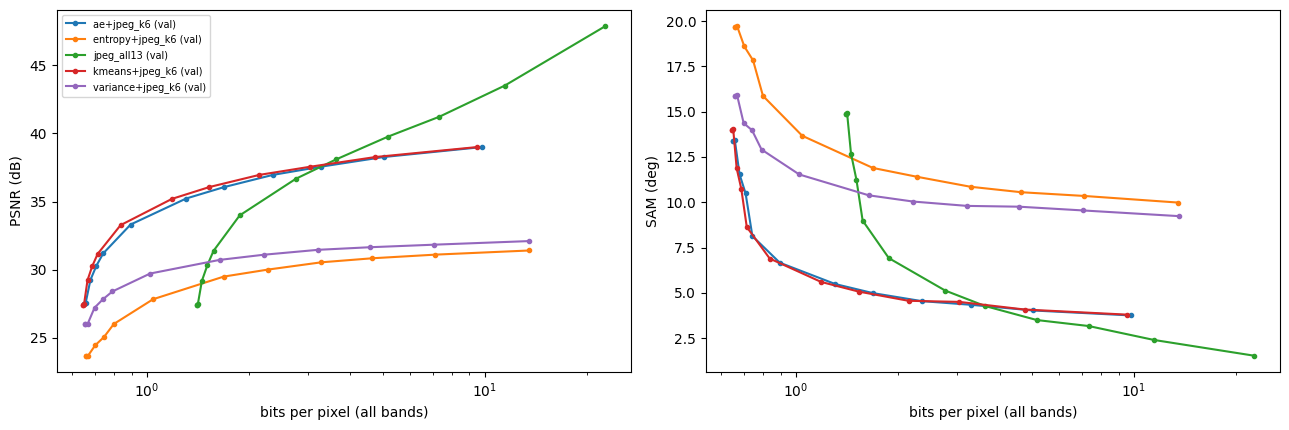

AE, k = 6, kept bands raw - by val region


,cr,bpp,psnr,ssim,sam,mae,mre
region,,,,,,,
gobi,2.1667,96.0,41.6876,0.9910,1.9804,0.0047,0.0146
murray_darling,2.1667,96.0,38.0070,0.9792,2.5099,0.0067,0.0212
tokyo_bay,2.1667,96.0,38.1784,0.9549,5.5281,0.0064,0.0254


In [10]:
# CELL 10: rate-distortion plot and by-region view
def rd_plot(dfs, path):
    labels = sorted({l for df in dfs.values() for l in e2e_matrix(df).label.unique()})
    col = {l: f"C{i}" for i, l in enumerate(labels)}
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
    for tag, df in dfs.items():
        for lab, g in e2e_matrix(df).groupby("label"):
            g = g.sort_values("bpp")
            kw = dict(c=col[lab], marker=".", ls="-" if tag == "val" else "--", label=f"{lab} ({tag})")
            ax[0].plot(g.bpp, g.PSNR, **kw)
            ax[1].plot(g.bpp, g.SAM, **kw)
    for a, yl in zip(ax, ["PSNR (dB)", "SAM (deg)"]):
        a.set_xscale("log"); a.set_xlabel("bits per pixel (all bands)"); a.set_ylabel(yl)
    ax[0].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

rd_plot({"val": val_res}, OUT / "a3_rd_val.png")

ae_main = val_res[(val_res.method == "ae") & (val_res.stage == "raw_kept") & (val_res.k == K_MAIN)]
print(f"AE, k = {K_MAIN}, kept bands raw - by val region")
display(ae_main.groupby("region")[["cr", "bpp", "psnr", "ssim", "sam", "mae", "mre"]].mean().round(4))

per-band MSE (x1e-4), k = 6


,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
method_group,,,,,,,,,,,,,
ae,2.08,0.00,0.86,4.83,4.26,1.55,0.83,3.92,0.00,0.00,0.00,0.00,0.00
entropy,10.32,9.56,6.55,5.28,2.68,0.00,0.00,0.00,0.00,39.00,61.75,0.00,0.00
kmeans,1.98,0.00,0.40,0.00,1.08,0.65,0.00,4.40,0.97,0.00,0.00,0.00,8.03
random,0.50,0.11,0.12,0.00,0.27,0.79,1.33,3.13,2.24,20.63,16.49,58.86,45.27
variance,7.50,5.08,2.71,0.00,1.06,0.66,0.00,0.00,0.00,44.08,62.66,0.00,0.00


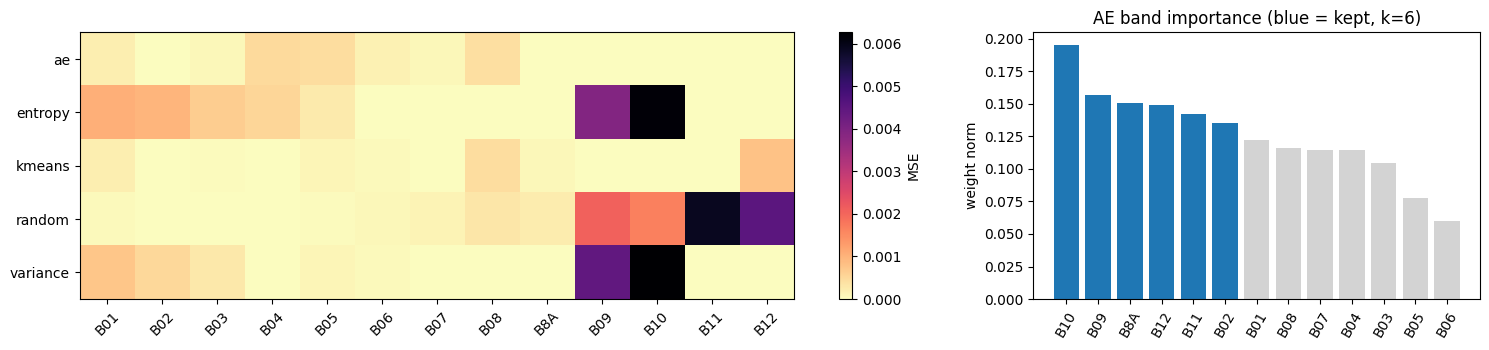

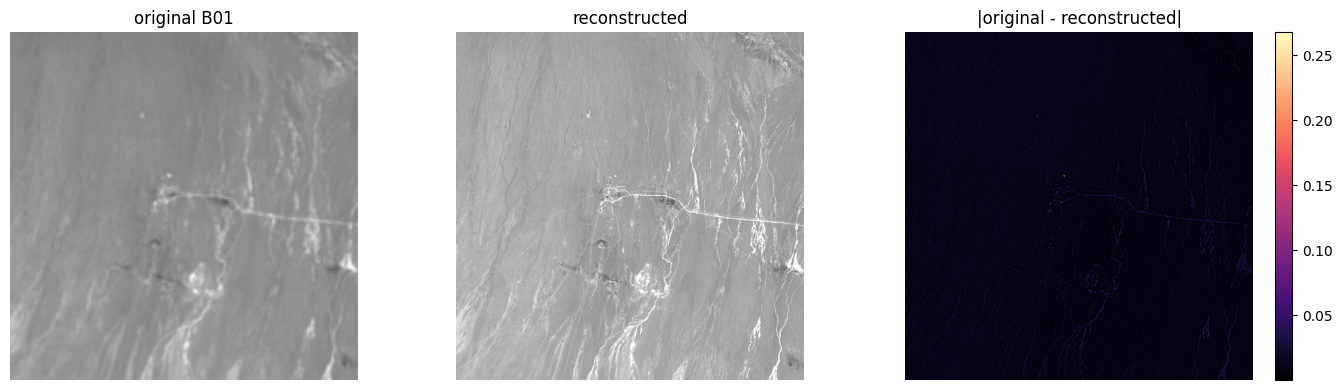

In [11]:
# CELL 11: where the loss sits - per-band matrix and a difference map (kept bands raw, k = K_MAIN)
bcols = [f"psnr_{b}" for b in BANDS]
bm = val_res[(val_res.stage == "raw_kept") & (val_res.k == K_MAIN)].copy()
bm[bcols] = 10 ** (-bm[bcols] / 10)                          # per-band PSNR back to per-band MSE (0 for kept bands)
band_mse = bm.groupby("method_group")[bcols].mean()
band_mse.columns = BANDS
print(f"per-band MSE (x1e-4), k = {K_MAIN}")
display((band_mse * 1e4).round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[2, 1]))
im = ax[0].imshow(band_mse.values, aspect="auto", cmap="magma_r")
ax[0].set_xticks(range(NB)); ax[0].set_xticklabels(BANDS, rotation=45)
ax[0].set_yticks(range(len(band_mse))); ax[0].set_yticklabels(band_mse.index)
plt.colorbar(im, ax=ax[0], label="MSE")
order = np.argsort(-importance); chosen = set(top_k(importance, K_MAIN))
ax[1].bar([BANDS[i] for i in order], importance[order],
          color=["tab:blue" if i in chosen else "lightgray" for i in order])
ax[1].set(title=f"AE band importance (blue = kept, k={K_MAIN})", ylabel="weight norm")
ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(OUT / "a3_band_loss_matrix.png", dpi=150); plt.show()

c_ae = next(c for c in configs if c["method"] == "ae" and c["k"] == K_MAIN)
x = load_patch(val_files[0])
pc = rebuild(x, c_ae)
b = int(((x - pc) ** 2).mean((1, 2)).argmax())               # worst reconstructed band
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
vmax = float(x[b].max())
ax[0].imshow(x[b], cmap="gray", vmin=0, vmax=vmax);   ax[0].set_title(f"original {BANDS[b]}")
ax[1].imshow(pc[b], cmap="gray", vmin=0, vmax=vmax);  ax[1].set_title("reconstructed")
d = ax[2].imshow(np.abs(x[b] - pc[b]), cmap="magma"); ax[2].set_title("|original - reconstructed|")
plt.colorbar(d, ax=ax[2], fraction=0.046)
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "a3_diff_map.png", dpi=150); plt.show()

In [12]:
# CELL 12: cost - model size, timings, memory
q_ref = 50 if 50 in QUALITIES else QUALITIES[len(QUALITIES) // 2]
x = load_patch(val_files[0])
sel = c_ae["sel"]

def timeit(fn, reps=5):
    fn(); t = time.perf_counter()
    for _ in range(reps): fn()
    return (time.perf_counter() - t) / reps * 1000

blobs = [jpeg_encode(x[b], q_ref) for b in sel]
t_enc = timeit(lambda: [jpeg_encode(x[b], q_ref) for b in sel])
t_dec = timeit(lambda: rebuild(x, c_ae, kept=np.stack([jpeg_decode(bl) for bl in blobs])))

cost = pd.DataFrame({"value": {
    "AE parameters": n_params,
    "AE size (KB)": round(n_params * 4 / 1024, 2),
    "regressor coefficients": int(c_ae["W"].size),
    "AE training time (s)": round(t_train, 1),
    f"encode k bands, q={q_ref} (ms/patch)": round(t_enc, 1),
    f"decode + regress, q={q_ref} (ms/patch)": round(t_dec, 1),
    "peak memory of this notebook (MB)": round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024),
}})
display(cost)

,value
AE parameters,208.00
AE size (KB),0.81
regressor coefficients,49.00
AE training time (s),32.40
"encode k bands, q=50 (ms/patch)",5.70
"decode + regress, q=50 (ms/patch)",26.80
peak memory of this notebook (MB),2175.00


test: 10/396 patches  (114s)
test: 20/396 patches  (227s)
test: 30/396 patches  (340s)
test: 40/396 patches  (454s)
test: 50/396 patches  (568s)
test: 60/396 patches  (683s)
test: 70/396 patches  (798s)
test: 80/396 patches  (913s)
test: 90/396 patches  (1026s)
test: 100/396 patches  (1141s)
test: 110/396 patches  (1255s)
test: 120/396 patches  (1370s)
test: 130/396 patches  (1484s)
test: 140/396 patches  (1599s)
test: 150/396 patches  (1714s)
test: 160/396 patches  (1830s)
test: 170/396 patches  (1945s)
test: 180/396 patches  (2059s)
test: 190/396 patches  (2173s)
test: 200/396 patches  (2288s)
test: 210/396 patches  (2403s)
test: 220/396 patches  (2520s)
test: 230/396 patches  (2637s)
test: 240/396 patches  (2756s)
test: 250/396 patches  (2873s)
test: 260/396 patches  (2990s)
test: 270/396 patches  (3107s)
test: 280/396 patches  (3222s)
test: 290/396 patches  (3336s)
test: 300/396 patches  (3451s)
test: 310/396 patches  (3565s)
test: 320/396 patches  (3680s)
test: 330/396 patches  (3

,method_group,k,CR,bpp,MSE,MAE,MRE,PSNR,SSIM,SAM
0,kmeans,4,3.25000,64.0,0.00101,0.01627,0.04457,32.32305,NaN,7.180670
1,ae,4,3.25000,64.0,0.00363,0.03206,0.09804,27.15545,NaN,16.378969
2,random,4,3.25000,64.0,0.01153,0.03317,0.05784,28.00623,NaN,14.460010
3,variance,4,3.25000,64.0,0.01272,0.04036,0.08170,25.75001,NaN,16.909491
4,entropy,4,3.25000,64.0,0.01281,0.04006,0.07778,26.09383,NaN,15.872360
5,kmeans,6,2.16667,96.0,0.00021,0.00624,0.01689,38.83038,0.97706,3.437210
6,ae,6,2.16667,96.0,0.00027,0.00743,0.02196,38.07340,0.97439,3.730180
7,random,6,2.16667,96.0,0.00347,0.01866,0.04085,30.27854,0.93119,9.642030
8,variance,6,2.16667,96.0,0.01118,0.02613,0.03561,29.50483,0.91821,13.103970
9,entropy,6,2.16667,96.0,0.01142,0.03084,0.05444,27.54424,0.87519,14.897740



[test] MSE original vs reconstructed, method x k


k,4,6,8
method_group,,,
ae,0.003634,0.000272,0.000173
entropy,0.012806,0.011420,0.006443
kmeans,0.001008,0.000206,0.000137
random,0.011527,0.003475,0.009658
variance,0.012720,0.011183,0.010642



[test] selection + JPEG vs JPEG on all 13 bands - PSNR (dB) at matched bits per pixel


,0.5 bpp,1 bpp,2 bpp,4 bpp,8 bpp
ae+jpeg_k6,NaN,32.81,35.57,36.85,37.55
entropy+jpeg_k6,NaN,24.65,26.14,26.90,27.20
jpeg_all13,NaN,NaN,33.31,38.46,42.22
kmeans+jpeg_k6,NaN,33.38,36.36,37.59,38.29
variance+jpeg_k6,NaN,26.65,28.18,28.84,29.13


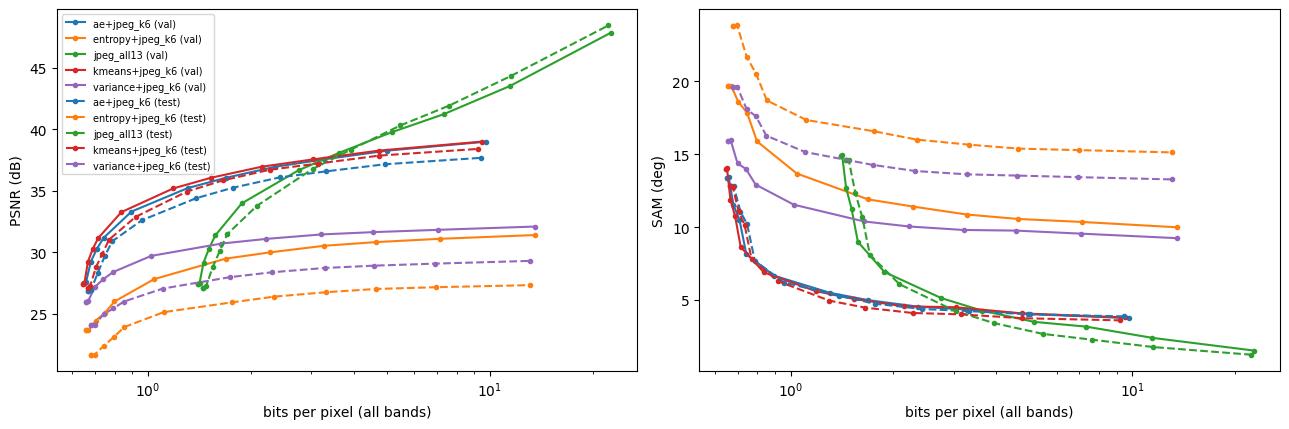


AE, k = 6, kept bands raw - by test region


,cr,bpp,psnr,ssim,sam,mae,mre
region,,,,,,,
everest_region,2.1667,96.0,32.5596,0.9636,2.7754,0.0121,0.0281
great_barrier_reef,2.1667,96.0,42.1488,0.9744,7.5880,0.0042,0.0199
lagos,2.1667,96.0,39.1165,0.9831,2.8225,0.0063,0.0203
northern_sweden,2.1667,96.0,36.2122,0.9656,5.3639,0.0099,0.0328
po_valley,2.1667,96.0,38.2904,0.9700,2.7858,0.0061,0.0199
rub_al_khali,2.1667,96.0,40.1131,0.9893,1.0455,0.0060,0.0107


In [13]:
# CELL 13: test set - same models, same bands, same regressors, nothing refitted
assert len(test_files) > 0, "no test patches found"
assert E.load_dn(test_files[0]).shape == (NB, H, W_)
test_res = run_split(test_files, "test", STRIDE_TEST)
test_s1, test_e2 = report(test_res, "test")
rd_plot({"val": val_res, "test": test_res}, OUT / "a3_rd_val_test.png")

print(f"\nAE, k = {K_MAIN}, kept bands raw - by test region")
display(test_res[(test_res.method == "ae") & (test_res.stage == "raw_kept") & (test_res.k == K_MAIN)]
        .groupby("region")[["cr", "bpp", "psnr", "ssim", "sam", "mae", "mre"]].mean().round(4))

In [14]:
# CELL 14: the project's metric table for Approach 3 (AE selection, k = K_MAIN)
def metric_table(df, q):
    a = df[(df.method == "ae") & (df.k == K_MAIN)]
    raw = a[a.stage == "raw_kept"].mean(numeric_only=True)
    enc = a[(a.stage == "select+jpeg") & (a.quality == q)].mean(numeric_only=True)
    ref = df[(df.stage == "jpeg_all13") & (df.quality == q)].mean(numeric_only=True)
    t = pd.DataFrame({"AE, kept bands raw": raw, f"AE + JPEG q={q}": enc, f"JPEG all 13 q={q}": ref})
    return t.loc[["cr", "bpp", "bps", "psnr", "ssim", "sam", "mae", "mre"]].round(4)

for tag, df in [("val", val_res), ("test", test_res)]:
    print(f"[{tag}]")
    display(metric_table(df, q_ref))
print("retained bands k =", K_MAIN, "| OA / AA / kappa: N/A, the data has no labels | redundancy, entropy: see the table after Cell 5")

# Add this to the bottom of Cell 14
print("\n" + "="*50)
print("SIZE & COMPRESSION MATRIX (AE, k =", K_MAIN, ")")
print("="*50)

# Size of one 512x512 patch (13 bands, 16-bit)
PATCH_BYTES = 13 * 512 * 512 * 2
ORIG_MB = PATCH_BYTES / (1024 * 1024)

a_test = test_res[(test_res.method == "ae") & (test_res.k == K_MAIN)]

# Extract sizes for raw selection and JPEG
raw_bytes = a_test[a_test.stage == "raw_kept"]["bytes"].mean()
jpeg_bytes = a_test[(a_test.stage == "select+jpeg") & (a_test.quality == q_ref)]["bytes"].mean()
all13_jpeg_bytes = test_res[(test_res.stage == "jpeg_all13") & (test_res.quality == q_ref)]["bytes"].mean()

size_df = pd.DataFrame({
    "Pipeline Stage": ["Original (13 bands, 16-bit)", "AE Selection (Raw k bands)", f"AE + JPEG (q={q_ref})", f"JPEG All 13 (q={q_ref})"],
    "Size (MB)": [ORIG_MB, raw_bytes / (1024*1024), jpeg_bytes / (1024*1024), all13_jpeg_bytes / (1024*1024)],
    "Compression Ratio (CR)": [1.0, ORIG_MB / (raw_bytes/(1024*1024)), ORIG_MB / (jpeg_bytes/(1024*1024)), ORIG_MB / (all13_jpeg_bytes/(1024*1024))]
})
display(size_df.round(3))

[val]


,"AE, kept bands raw",AE + JPEG q=50,JPEG all 13 q=50
cr,2.1667,108.7269,50.7946
bpp,96.0000,2.3569,5.1608
bps,7.3846,0.1813,0.3970
psnr,39.5478,36.9543,39.7595
ssim,0.9746,0.9293,0.9428
sam,3.5054,4.5411,3.4975
mae,0.0058,0.0104,0.0077
mre,0.0203,0.0344,0.0251


[test]


,"AE, kept bands raw",AE + JPEG q=50,JPEG all 13 q=50
cr,2.1667,110.5750,51.6753
bpp,96.0000,2.4282,5.4740
bps,7.3846,0.1868,0.4211
psnr,38.0734,36.0898,40.3110
ssim,0.9744,0.9357,0.9517
sam,3.7302,4.3779,2.6730
mae,0.0074,0.0116,0.0074
mre,0.0220,0.0331,0.0204


retained bands k = 6 | OA / AA / kappa: N/A, the data has no labels | redundancy, entropy: see the table after Cell 5

SIZE & COMPRESSION MATRIX (AE, k = 6 )


,Pipeline Stage,Size (MB),Compression Ratio (CR)
0,"Original (13 bands, 16-bit)",6.500,1.000
1,AE Selection (Raw k bands),3.000,2.167
2,AE + JPEG (q=50),0.076,85.659
3,JPEG All 13 (q=50),0.171,37.998


# EXPERIMENT
